# Brasil: geração do CSV de cinco minutos com potência, energia e estação solarimétrica

**Arquivo principal:** `data/interim/brasil/brasil_merge_5_minutos.csv`. Cada linha representa um intervalo de cinco minutos no horário de `America/Sao_Paulo`, para a usina `07-07FX` em 2025.

A pipeline lê os dois CSVs originais, converte `datetime` de UTC para o horário local e associa as leituras ao intervalo de cinco minutos imediatamente anterior. Registros repetidos do mesmo equipamento e intervalo são consolidados pela mediana dos valores numéricos finitos.

Em seguida, soma separadamente os oito inversores para produzir **potência AC, potência DC, energia diária, energia mensal e energia acumulada**, e associa todos os 55 canais físicos da estação pela mesma grade. O arquivo principal contém os totais da usina, sem colunas individuais de inversores. Cada total exige os oito valores disponíveis da respectiva grandeza; as ausências são preservadas e zero observado permanece zero.

**Interpretação da energia:** as colunas de energia são a soma dos estados dos contadores no horário registrado. Não representam energia produzida exclusivamente nos cinco minutos. Não se devem somar as leituras repetidas de um contador ao longo dos horários para obter energia diária. A validação diária cruzada dos contadores continua no experimento `teste_cronos_diario.ipynb`.

Execute de cima para baixo usando um kernel com as dependências do projeto. Neste computador, foi utilizado o ambiente `anomaly_detection`.


In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
from IPython.display import display, Image, Markdown

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/energia_transfer").is_dir())
if str(RAIZ / "src") not in sys.path:
    sys.path.insert(0, str(RAIZ / "src"))
from energia_transfer.brasil_merge_horarios import preparar_merge_brasil, gerar_figuras_merge, TOTAIS_INVERSORES, INVERSORES
from energia_transfer.dicionario_colunas import significado

resultado = preparar_merge_brasil(RAIZ)
base = resultado["usina"]
ARQUIVO_CSV = resultado["arquivo_usina"]
figuras = gerar_figuras_merge(resultado)
print("CSV principal gerado:", ARQUIVO_CSV)
print("Linhas:", len(base), "Colunas, incluindo o horário:", len(base.columns) + 1)


CSV principal gerado: C:\Users\camil\Documents\transfer-learning-energy-forecast-tcc\data\interim\brasil\brasil_merge_5_minutos.csv
Linhas: 105120 Colunas, incluindo o horário: 71


C:\Users\camil\Documents\transfer-learning-energy-forecast-tcc\src\energia_transfer\brasil_merge_horarios.py:83: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  alinhados[f'{coluna}__n_valores_finitos'] = grupo[coluna].count()
C:\Users\camil\Documents\transfer-learning-energy-forecast-tcc\src\energia_transfer\brasil_merge_horarios.py:84: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  alinhados[f'{coluna}__valores_divergentes'] = grupo[coluna].nunique().gt(1)
C:\Users\camil\Documents\transfer-learning-energy-forecast-tcc\src\energia

## 1. Estrutura do arquivo principal

Os totais de potência são apresentados em W e kW. Os totais de energia são apresentados em kWh, com contadores diário, mensal e acumulado separados. Cada coluna `__n_inversores` informa quantos equipamentos contribuíram com valor numérico finito para aquele total. As colunas da estação mantêm seus nomes originais; os canais vazios também são preservados.


In [2]:
descricao_totais = pd.DataFrame([
    ["potencia_total_w", "Potência ativa AC somada dos oito inversores", "W"],
    ["potencia_total_kw", "Potência ativa AC somada, dividida por 1000", "kW"],
    ["potencia_dc_total_w", "Potência DC somada dos oito inversores", "W"],
    ["potencia_dc_total_kw", "Potência DC somada, dividida por 1000", "kW"],
    ["energia_diaria_kwh", "Soma dos contadores diários no horário", "kWh"],
    ["energia_mensal_kwh", "Soma dos contadores mensais no horário", "kWh"],
    ["energia_acumulada_kwh", "Soma dos contadores acumulados no horário", "kWh"],
], columns=["Coluna", "Significado", "Unidade"])
display(descricao_totais)
display(pd.DataFrame([dict(coluna=c, significado_pt=significado(c)[0], unidade=significado(c)[1]) for c in resultado["meta"]["colunas_fisicas_estacao"]]))


,Coluna,Significado,Unidade
0,potencia_total_w,Potência ativa AC somada dos oito inversores,W
1,potencia_total_kw,"Potência ativa AC somada, dividida por 1000",kW
2,potencia_dc_total_w,Potência DC somada dos oito inversores,W
3,potencia_dc_total_kw,"Potência DC somada, dividida por 1000",kW
4,energia_diaria_kwh,Soma dos contadores diários no horário,kWh
5,energia_mensal_kwh,Soma dos contadores mensais no horário,kWh
6,energia_acumulada_kwh,Soma dos contadores acumulados no horário,kWh


,coluna,significado_pt,unidade
0,indice_albedo_medio,Índice de albedo medio,"adimensional, a confirmar"
1,gri_kwh_day_est,Irradiação do canal GRI (plano/componente a co...,"kWh/m², a confirmar"
2,albedo_tracker,Albedo associado ao rastreador solar,"adimensional, a confirmar"
3,gri_irr_med,Irradiância do canal GRI (plano/componente a c...,unidade e escala a confirmar
4,poa_kwh_hour,"Irradiação no plano dos módulos, horária","kWh/m², a confirmar"
5,precipitacao_acc,Precipitação acumulada,"mm, a confirmar"
6,dir_vento,Direção do vento,"graus, a confirmar"
7,poa_irradiancia,Irradiância no plano dos módulos,unidade e escala a confirmar
8,poa_irr_med,"Irradiância no plano dos módulos, média",unidade e escala a confirmar
9,air_speed_max,Velocidade máxima do vento,a confirmar


## 2. Exemplo do merge: totais e meteorologia na mesma linha

A primeira tabela apresenta intervalos com potência total e temperatura da estação disponíveis. Cada variável é mantida de forma independente: ausência de meteorologia não remove a energia ou potência, e ausência de um contador não remove os outros totais.


In [3]:
colunas = ["potencia_total_kw", "potencia_dc_total_kw", "energia_diaria_kwh", "energia_mensal_kwh", "energia_acumulada_kwh", "air_temperature_med", "ghi_irr_med"]
display(base.loc[base.potencia_total_kw.notna() & base.air_temperature_med.notna(), colunas].head(12))
DIA = "2025-02-01"
display(base.loc[DIA, colunas].head(24))


,potencia_total_kw,potencia_dc_total_kw,energia_diaria_kwh,energia_mensal_kwh,energia_acumulada_kwh,air_temperature_med,ghi_irr_med
horario_local,,,,,,,
2025-01-04 19:05:00,0.000,0.000,3996.0,21037.9,1060397.0,21.390013,-1.194333
2025-01-04 19:10:00,0.000,0.000,3996.0,21037.9,1060397.0,21.345009,-1.676500
2025-01-06 06:40:00,69.651,73.237,29.1,26564.5,1065924.0,20.299999,122.687187
2025-01-06 06:45:00,69.140,71.909,36.0,26571.4,1065932.0,19.996668,74.587845
2025-01-06 06:50:00,82.249,85.877,45.1,26580.5,1065940.0,20.591654,182.502853
2025-01-06 07:00:00,128.084,134.873,54.9,26590.3,1065948.0,21.114992,186.267136
2025-01-06 07:05:00,142.058,149.196,68.4,26603.9,1065963.0,21.945005,222.625153
2025-01-06 07:10:00,168.616,175.970,84.2,26619.6,1065978.0,22.942499,242.255363
2025-01-06 07:15:00,190.713,199.736,102.5,26637.9,1065997.0,23.469999,260.215179


,potencia_total_kw,potencia_dc_total_kw,energia_diaria_kwh,energia_mensal_kwh,energia_acumulada_kwh,air_temperature_med,ghi_irr_med
horario_local,,,,,,,
2025-02-01 00:00:00,0.0,0.0,0.0,0.0,1205540.0,NaN,NaN
2025-02-01 00:05:00,0.0,0.0,0.0,0.0,1205540.0,NaN,NaN
2025-02-01 00:10:00,0.0,0.0,0.0,0.0,1205540.0,NaN,NaN
2025-02-01 00:15:00,0.0,0.0,0.0,0.0,1205540.0,NaN,NaN
2025-02-01 00:20:00,0.0,0.0,0.0,0.0,1205540.0,NaN,NaN
2025-02-01 00:25:00,0.0,0.0,0.0,0.0,1205540.0,NaN,NaN
2025-02-01 00:30:00,0.0,0.0,0.0,0.0,1205540.0,NaN,NaN
2025-02-01 00:35:00,0.0,0.0,0.0,0.0,1205540.0,NaN,NaN
2025-02-01 00:40:00,0.0,0.0,0.0,0.0,1205540.0,NaN,NaN


## 3. Conferência da grade e das somas

O calendário completo de 2025 possui 105120 intervalos. As verificações abaixo asseguram que cada horário aparece uma vez e que cada total reproduz a soma dos oito equipamentos, preservando ausências quando faltam parcelas. A contagem de contribuintes é feita separadamente por grandeza.


In [4]:
assert len(base) == 105120
assert base.index.is_unique
assert (base.index.to_series().diff().dropna() == pd.Timedelta(minutes=5)).all()
for origem, destino in TOTAIS_INVERSORES.items():
    partes = resultado["base"][[f"{origem}__{nome}" for nome in INVERSORES]]
    esperado = partes.sum(axis=1, min_count=8)
    np.testing.assert_allclose(base[destino], esperado, equal_nan=True)
    assert base[destino].notna().equals(base[f"{destino}__n_inversores"].eq(8))
np.testing.assert_allclose(base.potencia_total_kw, base.potencia_total_w / 1000, equal_nan=True)
np.testing.assert_allclose(base.potencia_dc_total_kw, base.potencia_dc_total_w / 1000, equal_nan=True)
print("Grade e somas conferidas em todos os intervalos.")


Grade e somas conferidas em todos os intervalos.


## 4. Disponibilidade das colunas do CSV

A cobertura é calculada separadamente para cada total e cada canal da estação. A ausência de uma parcela impede apenas o respectivo total; não se preenchem leituras por interpolação e não se disponibilizam somas parciais como totais.


,ano,n_inversores,intervalos_esperados,intervalos_com_potencia_total,cobertura_potencia_total_pct,intervalos_potencia_incompleta,intervalos_sem_registros
0,2025,8,105120,82787,78.754756,3140,19193


,variavel,intervalos_esperados,intervalos_disponiveis,cobertura_pct
0,potencia_total_w,105120,82787,78.754756
1,potencia_total_kw,105120,82787,78.754756
2,potencia_dc_total_w,105120,82787,78.754756
3,potencia_dc_total_kw,105120,82787,78.754756
4,energia_diaria_kwh,105120,82787,78.754756
...,...,...,...,...
57,precipitacao_acc_day,105120,33383,31.757040
58,poa_kwh_acc_est,105120,33383,31.757040
59,gri_irr_max,105120,62,0.058980
60,ghi_kwh_acc_est,105120,33383,31.757040


,n_inversores_com_potencia,potencia_total_kw,energia_diaria_kwh,energia_acumulada_kwh
horario_local,,,,
2025-01-02 20:35:00,1,NaN,NaN,NaN
2025-01-04 12:20:00,1,NaN,NaN,NaN
2025-01-04 17:25:00,1,NaN,NaN,NaN
2025-01-06 06:30:00,7,NaN,NaN,NaN
2025-01-06 08:10:00,7,NaN,NaN,NaN
2025-01-06 10:10:00,1,NaN,NaN,NaN
2025-01-06 13:50:00,4,NaN,NaN,NaN
2025-01-07 23:35:00,1,NaN,NaN,NaN
2025-01-13 09:45:00,1,NaN,NaN,NaN


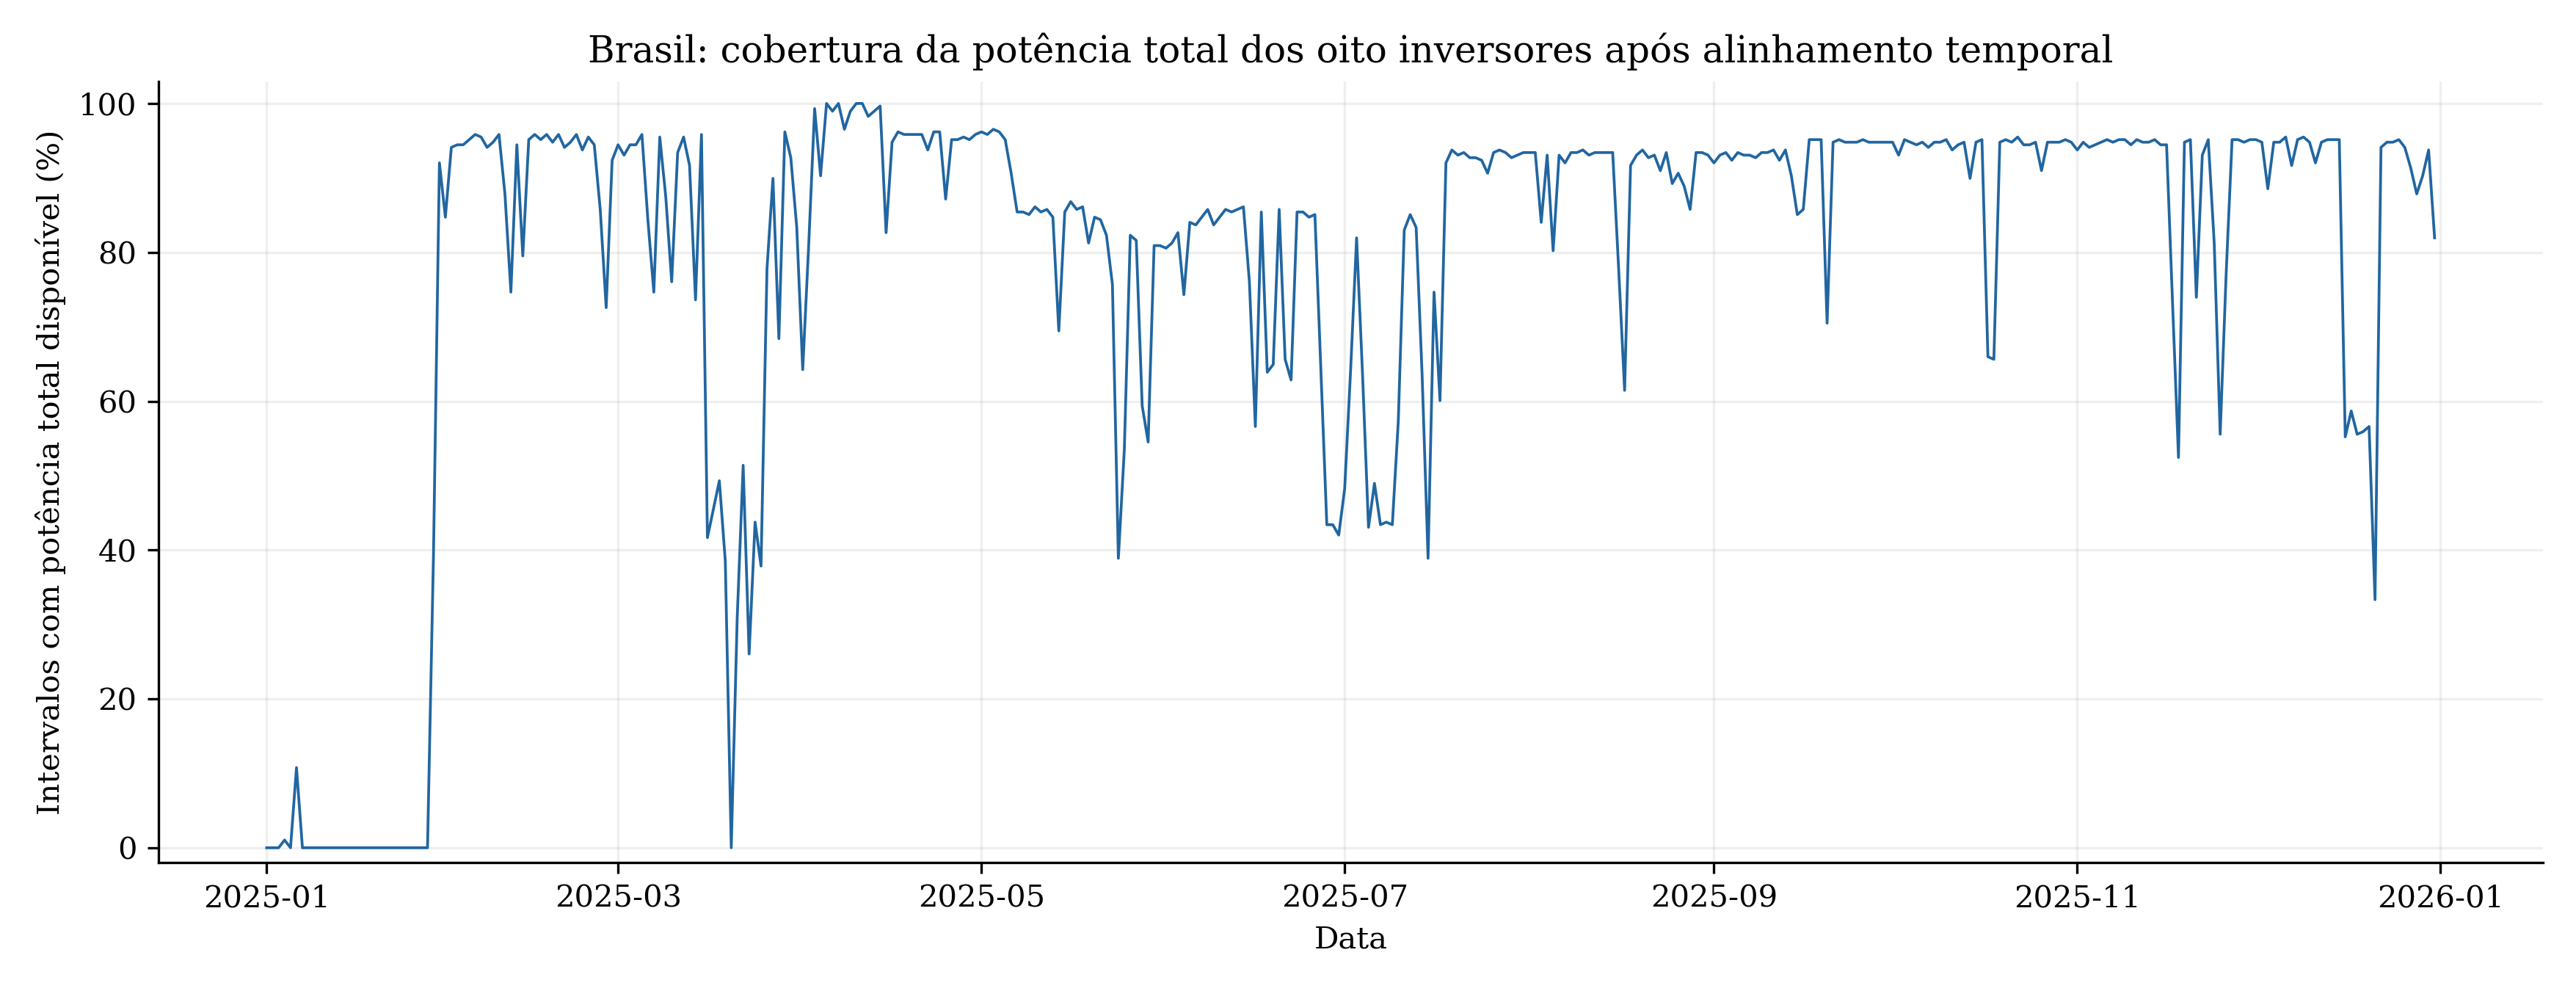

**Cobertura da potência total após alinhamento temporal.** Cobertura diária da soma das potências dos oito inversores da usina 07-07FX, após alinhamento em intervalos de cinco minutos no horário local. O denominador é de 288 intervalos por dia. A potência total é disponibilizada somente quando os oito inversores possuem valores numéricos finitos no intervalo; registros repetidos são consolidados pela mediana. Os valores ausentes são preservados.

In [5]:
display(resultado["resumo"])
display(resultado["cobertura_usina"])
display(base.loc[base.n_inversores_com_potencia.between(1, 7), ["n_inversores_com_potencia", "potencia_total_kw", "energia_diaria_kwh", "energia_acumulada_kwh"]].head(12))
for figura in figuras:
    display(Image(filename=str(resultado["pasta"] / (figura["arquivo"] + ".png")), width=1050))
    display(Markdown("**Cobertura da potência total após alinhamento temporal.** " + figura["legenda"]))


## 5. Rastreabilidade e saídas

O arquivo para uso é **`data/interim/brasil/brasil_merge_5_minutos.csv`**. Ele reúne potência e energia totais dos inversores e os canais da estação em uma linha por intervalo de cinco minutos.

Os arquivos detalhados por inversor, mapas dos horários originais, cobertura e manifesto ficam em `reports/tcc/brasil_merge_horarios/`. O arquivo detalhado `brasil_merge_5min.csv` dessa pasta é um apoio de auditoria e inclui os equipamentos individuais. Os CSVs originais e os alvos do experimento diário são preservados.


In [6]:
print("Arquivo principal:", ARQUIVO_CSV)
print("Auditoria:", resultado["pasta"])
display(pd.DataFrame({"Inversores": resultado["meta"]["inversores"], "Estação": resultado["meta"]["estacao"]}))
print(json.dumps(resultado["meta"], ensure_ascii=False, indent=2))


Arquivo principal: C:\Users\camil\Documents\transfer-learning-energy-forecast-tcc\data\interim\brasil\brasil_merge_5_minutos.csv
Auditoria: C:\Users\camil\Documents\transfer-learning-energy-forecast-tcc\reports\tcc\brasil_merge_horarios
{
  "usina": "07-07FX",
  "ano": 2025,
  "fuso": "America/Sao_Paulo",
  "regra_temporal": "datetime UTC convertido para horário local; floor de 5 min; intervalo [t, t+5 min)",
  "regra_duplicatas": "Mediana dos valores numéricos finitos por equipamento e intervalo",
  "regra_potencia": "Soma no mesmo intervalo, somente com oito valores disponíveis; W / 1000 = kW",
  "regra_energia": "Soma dos oito contadores no mesmo horário, separadamente para energia diária, mensal e acumulada. Não representa energia gerada nos cinco minutos.",
  "arquivo_usina": "data\\interim\\brasil\\brasil_merge_5_minutos.csv",
  "ausencias": "Sem interpolação, preenchimento ou substituição de ausências por zero",
  "ressalvas": [
    "Alinhamento por intervalo não garante simulta

,Inversores,Estação
linhas_usina,733389,35535
linhas_no_ano,733389,35535
linhas_com_chave_invalida,0,0
linhas_fora_ano,0,0
grupos_equipamento_intervalo,680772,33383
registros_excedentes_consolidados,52617,2152
registros_desalinhados,223941,1494
